# Task 1.2 - Logistic Regression

## Crime Case Classification

### Objective

The objective of this task is to predict whether a crime case is **closed** using the provided `crime_train.csv` and `crime_test.csv` datasets.

The Logistic Regression model is implemented **from scratch** using NumPy for matrix calculations. No machine-learning library is used to create the model.

The training dataset is used to learn the model parameters. The supplied test dataset is used only for evaluation and prediction, and its labels are **never used to update the model parameters**.

### Evaluation metric

For this classification task, the required evaluation metric is **accuracy**.

$$
Accuracy = \frac{\text{Number of correct predictions}}{\text{Total predictions}} \times 100
$$


## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the datasets

In [2]:
train_data = pd.read_csv("crime_train.csv")
test_data = pd.read_csv("crime_test.csv")

print("Training shape:", train_data.shape)
print("Testing shape :", test_data.shape)

Training shape: (22489, 12)
Testing shape : (9639, 12)


## 3. Understand the data

In [3]:
print("Training columns:")
print(train_data.columns.tolist())

print("\nFirst five training rows:")
display(train_data.head())

print("\nMissing values in training data:")
display(train_data.isnull().sum())

print("\nTarget distribution:")
display(train_data["closed"].value_counts())

Training columns:
['Unnamed: 0', 'Num', 'case_filed', 'city', 'area', 'crime_description', 'age', 'sex', 'weapon', 'domain', 'police_department', 'closed']

First five training rows:


,Unnamed: 0,Num,case_filed,city,area,crime_description,age,sex,weapon,domain,police_department,closed
0,19794,19795,04-04-2022 18:00,Mumbai,307,VEHICLE - STOLEN,63.0,X,Poison,Violent Crime,12.0,No
1,13762,13763,07-27-2021 10:00,Surat,504,ROBBERY,57.0,F,Explosives,Violent Crime,3.0,No
2,30311,30312,06-16-2023 23:00,Thane,493,ASSAULT,33.0,F,Firearm,Violent Crime,18.0,No
3,5043,5044,07-29-2020 03:00,Ahmedabad,169,PUBLIC INTOXICATION,76.0,F,Knife,Other Crime,3.0,No
4,35008,35009,12-29-2023 16:00,Mumbai,133,PUBLIC INTOXICATION,13.0,M,NaN,Other Crime,13.0,No



Missing values in training data:


Unnamed: 0              0
Num                     0
case_filed              0
city                    0
area                    0
crime_description       0
age                     0
sex                     0
weapon               3272
domain                  0
police_department       0
closed                  0
dtype: int64


Target distribution:


closed
Yes    11253
No     11236
Name: count, dtype: int64

## 4. Prepare the target

The target column is `closed`.

It contains the categorical values `Yes` and `No`. Logistic Regression needs numerical class labels, so we encode:

- `Yes` → `1`
- `No` → `0`

The target of the test dataset is kept separately so that we can calculate the required testing accuracy. It is not used during gradient updates.

In [4]:
y_train = (train_data["closed"].str.strip().str.lower() == "yes").astype(float).to_numpy().reshape(-1, 1)
y_test = (test_data["closed"].str.strip().str.lower() == "yes").astype(float).to_numpy().reshape(-1, 1)

print("Training class counts:")
print(pd.Series(y_train.ravel()).value_counts().sort_index())

print("\nTesting class counts:")
print(pd.Series(y_test.ravel()).value_counts().sort_index())

Training class counts:
0.0    11236
1.0    11253
Name: count, dtype: int64

Testing class counts:
0.0    4816
1.0    4823
Name: count, dtype: int64


## 5. Feature preprocessing

We remove:

- `closed`, because it is the target.
- `Unnamed: 0` and `Num`, because they are row/index identifiers rather than meaningful crime characteristics.

The `case_filed` string is converted into useful numerical date/time features: year, month, day, hour, day of week, and day of year.

The missing `weapon` values are treated as a separate category called `Unknown`.

Categorical variables are converted using one-hot encoding. Numerical features are standardized using statistics calculated **only from the training data**, and the same training statistics are then applied to the test data.

In [5]:
X_train_df = train_data.drop(columns=["closed", "Unnamed: 0", "Num"]).copy()
X_test_df = test_data.drop(columns=["closed", "Unnamed: 0", "Num"]).copy()

# Convert date/time into numerical features
train_dt = pd.to_datetime(X_train_df.pop("case_filed"), errors="coerce")
test_dt = pd.to_datetime(X_test_df.pop("case_filed"), errors="coerce")

for df, dt in [(X_train_df, train_dt), (X_test_df, test_dt)]:
    df["year"] = dt.dt.year
    df["month"] = dt.dt.month
    df["day"] = dt.dt.day
    df["hour"] = dt.dt.hour
    df["dayofweek"] = dt.dt.dayofweek
    df["dayofyear"] = dt.dt.dayofyear

# Missing weapons are given their own category
X_train_df["weapon"] = X_train_df["weapon"].fillna("Unknown")
X_test_df["weapon"] = X_test_df["weapon"].fillna("Unknown")

# One-hot encode categorical features
categorical_columns = X_train_df.select_dtypes(include=["object"]).columns.tolist()

X_train_df = pd.get_dummies(
    X_train_df,
    columns=categorical_columns,
    dtype=float
)

X_test_df = pd.get_dummies(
    X_test_df,
    columns=categorical_columns,
    dtype=float
)

# Make test columns match training columns exactly
X_test_df = X_test_df.reindex(columns=X_train_df.columns, fill_value=0)

# Fill numerical missing values using medians from TRAINING data only
numeric_columns = X_train_df.select_dtypes(include=np.number).columns
train_medians = X_train_df[numeric_columns].median()

X_train_df[numeric_columns] = X_train_df[numeric_columns].fillna(train_medians)
X_test_df[numeric_columns] = X_test_df[numeric_columns].fillna(train_medians)

# Standardize using TRAINING statistics only
train_mean = X_train_df.mean(axis=0)
train_std = X_train_df.std(axis=0, ddof=0)
train_std[train_std == 0] = 1

X_train_df = (X_train_df - train_mean) / train_std
X_test_df = (X_test_df - train_mean) / train_std

X_train = X_train_df.to_numpy(dtype=float)
X_test = X_test_df.to_numpy(dtype=float)

print("Final training feature matrix:", X_train.shape)
print("Final testing feature matrix :", X_test.shape)

Final training feature matrix: (22489, 73)
Final testing feature matrix : (9639, 73)


## 6. Logistic Regression from scratch

Logistic Regression first calculates a linear score:

$$
z = Xw + b
$$

This score is converted into a probability using the sigmoid function:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

The probability is converted into a class using a threshold of `0.5`.

```text
probability >= 0.5  ->  class 1 (Yes)
probability <  0.5  ->  class 0 (No)
```

In [6]:
def sigmoid(z):
    # Clipping prevents numerical overflow in exp()
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def predict_probability(X, w, b):
    return sigmoid(np.dot(X, w) + b)


def predict_class(X, w, b):
    probabilities = predict_probability(X, w, b)
    return (probabilities >= 0.5).astype(int)

## 7. Binary Cross-Entropy loss

For binary classification we use Binary Cross-Entropy:

$$
J=-\frac{1}{m}\sum_{i=1}^{m}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
$$

where `p` is the predicted probability.

The aim of training is to minimize this loss.

In [7]:
def binary_cross_entropy(y, probabilities):
    epsilon = 1e-15
    probabilities = np.clip(probabilities, epsilon, 1 - epsilon)

    return -np.mean(
        y * np.log(probabilities)
        + (1 - y) * np.log(1 - probabilities)
    )

## 8. Accuracy function

The assignment specifies **accuracy** as the evaluation metric for Logistic Regression.

In [8]:
def accuracy(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return np.mean(predictions == y_true) * 100

## 9. Initialize the model

Each feature receives a weight. The bias starts at zero.

Initially the model has not learned anything, so the weights are all zero.

In [9]:
number_of_features = X_train.shape[1]

w = np.zeros((number_of_features, 1))
b = 0.0

print("Number of features:", number_of_features)
print("Initial weight shape:", w.shape)
print("Initial bias:", b)

Number of features: 73
Initial weight shape: (73, 1)
Initial bias: 0.0


## 10. Gradient Descent

For Logistic Regression, the gradients are:

$$
dw=\frac{1}{m}X^T(p-y)
$$

$$
db=\frac{1}{m}\sum(p-y)
$$

The parameters are updated using:

$$
w=w-\alpha dw
$$

$$
b=b-\alpha db
$$

where `alpha` is the learning rate.

One epoch here means one full-batch pass over the entire training dataset followed by one parameter update.

In [10]:
learning_rate = 0.1
epochs = 100

history = []

for epoch in range(1, epochs + 1):
    # Forward pass on TRAINING data
    train_probabilities = predict_probability(X_train, w, b)

    # Calculate gradients from TRAINING data only
    errors = train_probabilities - y_train

    m = len(y_train)

    dw = np.dot(X_train.T, errors) / m
    db = np.mean(errors)

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # Evaluate AFTER the update
    train_probabilities = predict_probability(X_train, w, b)
    test_probabilities = predict_probability(X_test, w, b)

    train_loss = binary_cross_entropy(y_train, train_probabilities)
    train_accuracy = accuracy(y_train, train_probabilities)
    test_accuracy = accuracy(y_test, test_probabilities)

    history.append([
        epoch,
        train_loss,
        train_accuracy,
        test_accuracy
    ])

history = pd.DataFrame(
    history,
    columns=["epoch", "training_loss", "training_accuracy", "testing_accuracy"]
)

print("Training completed.")

Training completed.


## 11. Epoch-wise training and testing accuracy

The assignment requires training and testing accuracy values for the epochs. The following table records them for every epoch.

The test labels are used **only to calculate the reported testing accuracy**. They are never used in the gradient calculation or parameter update.

In [11]:
pd.set_option("display.max_rows", 100)
display(history)

,epoch,training_loss,training_accuracy,testing_accuracy
0,1,0.693093,51.629686,49.413840
1,2,0.693042,51.634132,49.310094
2,3,0.692994,51.589666,49.216724
3,4,0.692949,51.545200,49.216724
4,5,0.692908,51.687492,49.227098
5,6,0.692868,51.736404,49.247847
6,7,0.692832,51.731958,49.195975
7,8,0.692797,51.665259,49.227098
8,9,0.692765,51.674152,49.175226
9,10,0.692734,51.616346,49.195975


## 12. Plot training loss

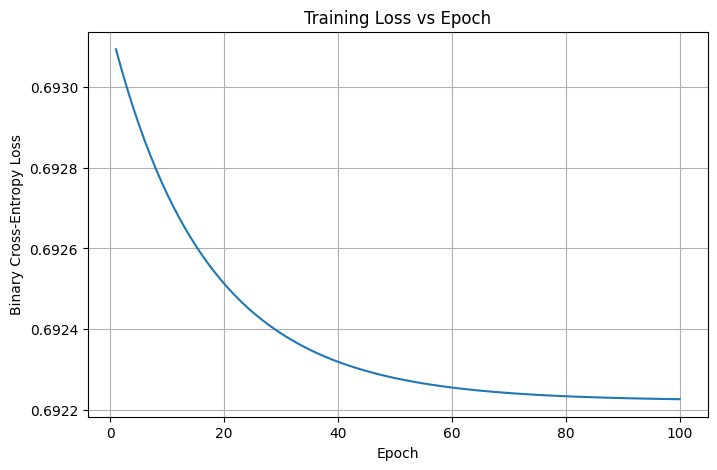

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["training_loss"])
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss vs Epoch")
plt.grid(True)
plt.show()

## 13. Plot training and testing accuracy

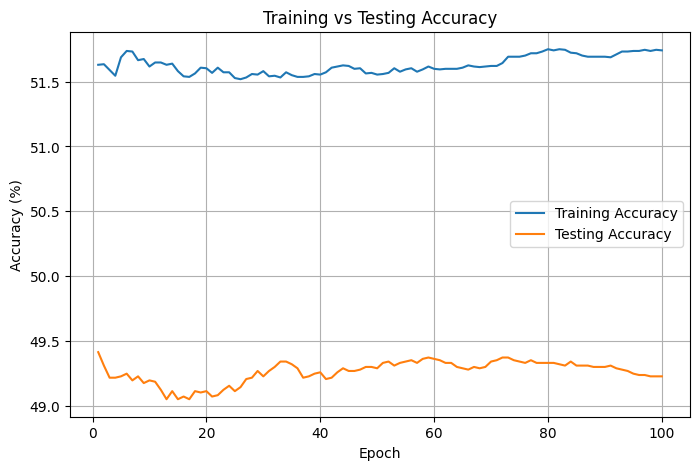

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["training_accuracy"], label="Training Accuracy")
plt.plot(history["epoch"], history["testing_accuracy"], label="Testing Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Testing Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 14. Final evaluation

The final model is evaluated on the supplied test dataset.

For reference, the majority-class baseline is also shown. Since the test set contains almost equal numbers of `Yes` and `No` cases, a classifier that always predicts the majority class is expected to achieve about 50% accuracy.

This dataset produces weak predictive signal for the available features, so an accuracy close to 50% is a legitimate result. The model should not be artificially tuned to produce a higher number.

In [14]:
final_test_probabilities = predict_probability(X_test, w, b)
final_test_predictions = (final_test_probabilities >= 0.5).astype(int)

final_train_accuracy = accuracy(
    y_train,
    predict_probability(X_train, w, b)
)

final_test_accuracy = accuracy(
    y_test,
    final_test_probabilities
)

majority_baseline = max(
    np.mean(y_test == 0),
    np.mean(y_test == 1)
) * 100

print(f"Final Training Accuracy : {final_train_accuracy:.2f}%")
print(f"Final Testing Accuracy  : {final_test_accuracy:.2f}%")
print(f"Majority-Class Baseline : {majority_baseline:.2f}%")

Final Training Accuracy : 51.74%
Final Testing Accuracy  : 49.23%
Majority-Class Baseline : 50.04%


## 15. Test predictions

The final model predicts whether each case in `crime_test.csv` is closed.

`1` represents **Yes/Closed** and `0` represents **No/Not Closed**.

In [15]:
predictions_output = test_data.copy()

predictions_output["predicted_probability"] = final_test_probabilities.ravel()
predictions_output["predicted_closed"] = np.where(
    final_test_predictions.ravel() == 1,
    "Yes",
    "No"
)

display(predictions_output.head())

predictions_output.to_csv(
    "logistic_regression_test_predictions.csv",
    index=False
)

history.to_csv(
    "logistic_regression_epoch_history.csv",
    index=False
)

print("Prediction file saved as logistic_regression_test_predictions.csv")
print("Epoch history saved as logistic_regression_epoch_history.csv")

,Unnamed: 0,Num,case_filed,city,area,crime_description,age,sex,weapon,domain,police_department,closed,predicted_probability,predicted_closed
0,32079,32080,08-29-2023 15:00,Pune,589,VEHICLE - STOLEN,57.0,M,Explosives,Violent Crime,13.0,Yes,0.479338,No
1,39119,39120,06-17-2024 23:00,Ahmedabad,596,HOMICIDE,49.0,F,Other,Other Crime,10.0,Yes,0.516592,Yes
2,34553,34554,12-10-2023 17:00,Mumbai,337,PUBLIC INTOXICATION,41.0,M,Firearm,Other Crime,12.0,Yes,0.478348,No
3,29684,29685,05-21-2023 20:00,Hyderabad,252,TRAFFIC VIOLATION,15.0,F,Other,Traffic Fatality,11.0,Yes,0.540397,Yes
4,20673,20674,05-11-2022 09:00,Hyderabad,340,VEHICLE - STOLEN,42.0,F,Other,Violent Crime,18.0,Yes,0.529444,Yes


Prediction file saved as logistic_regression_test_predictions.csv
Epoch history saved as logistic_regression_epoch_history.csv


## 16. Conclusion

A Logistic Regression classifier was successfully implemented from scratch using NumPy.

The model uses:

- One-hot encoding for categorical features
- Date/time feature extraction
- Median imputation based on training data
- Standardization based on training data
- Sigmoid activation
- Binary Cross-Entropy loss
- Full-batch Gradient Descent

The supplied test set was not used to train the model. Its labels were used only for the required testing-accuracy calculation.

The final testing accuracy should be interpreted together with the approximately 50% majority baseline. A result close to 50% indicates that the available features have little useful linear signal for predicting whether a case is closed.